# Internship Research Prime
## Auditable preprocessing and resistance prediction in Salmonella

**Question.** How do missing-value handling and categorical encoding affect
prediction of source-reported antibiotic resistance from isolate metadata
and existing AMRFinderPlus annotations?

The primary task is **ampicillin resistant versus susceptible**. Tetracycline
and ciprofloxacin are secondary. The fixed main configuration is
**onehot_median_flags**; controlled ablations hold logistic regression fixed.
Recorded SNP/BioSample components are separated before data-adaptive operations.

The frozen source contains **142,338 assays, 9,977 assembled isolate records,
and 9,976 BioSamples**. These are different denominators. This notebook loads
and inspects the delivered artifacts, reproduces small transformation examples,
and checks frozen-model inference. It **does not rerun the full research pipeline**.
This is computational methodology work using public observations, with no
claim of novel gene discovery, representative prevalence or clinical validity.


In [1]:
import sys, json, hashlib, platform
from pathlib import Path
from collections import Counter
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'data/raw/acquisition_manifest.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/preprocess.py').exists(), 'Run this notebook from the project or notebooks directory.'
sys.path.insert(0, str(ROOT / 'src'))
from preprocess import measurement, json_rows, digest

manifest = json.loads((ROOT / 'data/raw/acquisition_manifest.json').read_text())
prep = json.loads((ROOT / 'results/preprocessing_summary.json').read_text())
model_dir = ROOT / 'results/model_study'
study = json.loads((model_dir / 'summary.json').read_text())
source_checks = []
for item in manifest['downloads']:
    actual = digest(ROOT / item['file'])
    assert actual == item['sha256'], f"Raw file changed: {item['file']}"
    source_checks.append({'collection': item['collection'], 'records': item['records'],
                          'bytes': item['bytes'], 'sha256_verified': actual == item['sha256']})
print('Interpreter:', sys.executable, '| Python:', platform.python_version())
print('Frozen acquisition UTC:', manifest['started_at_utc'], 'to', manifest['completed_at_utc'])
display(pd.DataFrame(source_checks))
print('Raw SHA256 checks passed. Sorted IDs and unchanged counts do not imply a transactional live snapshot.')


Interpreter: /tmp/shadman_amr_venv/bin/python | Python: 3.12.3
Frozen acquisition UTC: 2026-10-18T06:59:08.888775+00:00 to 2026-10-18T07:04:14.289867+00:00


,collection,records,bytes,sha256_verified
0,ast,142338,85421138,True
1,isolates,9977,33101955,True


Raw SHA256 checks passed. Sorted IDs and unchanged counts do not imply a transactional live snapshot.


### 1. Source structure and units of analysis

NCBI's [AST documentation](https://www.ncbi.nlm.nih.gov/pathogens/docs/ast/)
defines an AST row as an individual laboratory test. The linked isolate table
supplies assembly summaries, annotations and collection metadata. The public
source labels receive basic quality checks, rather than full method/value review
([source limitations](https://www.ncbi.nlm.nih.gov/pathogens/ast/)).

We retain the source ID, check BioSample/assembly agreement, preserve repeated
assays, and form resolved **BioSample-antibiotic** targets. Repeated antibiotics
are useful long-format data; repeated labels are not independent votes.
The one BioSample linked to two assemblies is conservatively quarantined.


In [2]:
schema = json.loads((ROOT / 'results/audit/schema_audit.json').read_text())
schema_rows = []
selected_fields = {'id','biosample_acc','target_acc','antibiotic','phenotype','mic','mic_secondary',
                   'disk_diffusion','measurement_sign','platform','host','AMR_genotypes',
                   'AMR_genotypes_core','amrfinderplus_applied','collection_date','species_taxid'}
for collection, info in schema.items():
    for field, info_field in info['fields'].items():
        if field in selected_fields:
            schema_rows.append(dict(collection=collection, field=field, **info_field))
display(pd.DataFrame(schema_rows))
raw_biosamples, raw_targets, raw_drugs = set(), set(), set()
for row in json_rows(ROOT / 'data/raw/ncbi_salmonella_ast.jsonl'):
    raw_biosamples.add(row['biosample_acc']); raw_targets.add(row['target_acc']); raw_drugs.add(row['antibiotic'])
assert (len(raw_targets), len(raw_biosamples), len(raw_drugs)) == (9977, 9976, 72)
features = pd.read_csv(ROOT / 'data/processed/isolate_features.csv.gz')
pairs = pd.read_csv(ROOT / 'data/processed/phenotype_pairs.csv.gz')
display(pd.DataFrame({'unit': ['Raw AST observations','Raw assembly records','Raw BioSamples',
                              'Retained unique BioSamples','Resolved BioSample-drug pairs'],
                      'count': [prep['raw_ast_rows'], prep['raw_isolate_records'], len(raw_biosamples),
                                len(features), len(pairs)]}))
drug_denominators = pairs.groupby('antibiotic').agg(
    biosample_drug_pairs=('biosample_acc','size'),
    eligible_binary_pairs=('status',lambda x: x.eq('eligible_binary').sum()))
display(drug_denominators.loc[['ampicillin','tetracycline','ciprofloxacin']])


,collection,field,present,absent,types
0,isolates,AMR_genotypes,9874,103,{'list': 9874}
1,isolates,AMR_genotypes_core,7076,2901,{'list': 7076}
2,isolates,amrfinderplus_applied,9977,0,{'int': 9977}
3,isolates,biosample_acc,9977,0,{'str': 9977}
4,isolates,collection_date,9937,40,{'str': 9937}
5,isolates,host,629,9348,{'str': 629}
6,isolates,id,9977,0,{'str': 9977}
7,isolates,species_taxid,9977,0,{'int': 9977}
8,isolates,target_acc,9977,0,{'str': 9977}
9,ast,antibiotic,142338,0,{'str': 142338}


,unit,count
0,Raw AST observations,142338
1,Raw assembly records,9977
2,Raw BioSamples,9976
3,Retained unique BioSamples,9975
4,Resolved BioSample-drug pairs,142299


,biosample_drug_pairs,eligible_binary_pairs
antibiotic,,
ampicillin,9916,9876
tetracycline,9884,9814
ciprofloxacin,9876,9584


### 2. Preserve assay semantics before building labels

MIC **<=4 mg/L** is the interval **(0,4]**, while **>8 mg/L** has an open
lower boundary. A combination such as **32/4** contains two reported
concentrations; dividing them changes the meaning. The source comparator
is not independently invented for the second component. Disk diffusion
uses millimetres and remains separate from MIC.

The small examples below test transformation semantics. The following
platform disagreement comes from actual raw observations and is quarantined
for the binary target rather than resolved by a guessed breakpoint.


In [3]:
examples = []
for value, sign, kind in [('4','<=','mic'), ('8','>','mic'), ('32/4','==','mic'),
                          ('20','==','disk'), (None,'==','mic')]:
    parsed = measurement(value, sign, kind)
    examples.append({'example': f'{kind} {sign} {value}', 'status': parsed[kind+'_status'],
                     'lower': parsed[kind+'_1_lower'], 'upper': parsed[kind+'_1_upper'],
                     'lower_closed': parsed[kind+'_1_lower_closed'],
                     'upper_closed': parsed[kind+'_1_upper_closed'],
                     'components': parsed[kind+'_components']})
display(pd.DataFrame(examples))
conflict = [r for r in json_rows(ROOT / 'data/raw/ncbi_salmonella_ast.jsonl')
            if r['target_acc']=='PDT000555592.1' and r['antibiotic']=='piperacillin-tazobactam']
display(pd.DataFrame(conflict)[['id','biosample_acc','antibiotic','phenotype',
                                'measurement_sign','mic','mic_secondary','standard','platform']])
assert {r['phenotype'] for r in conflict} == {'susceptible','resistant'}
display(pd.read_csv(ROOT / 'results/audit/censoring_counts.csv'))
print('Combination-MIC assays:', prep['combination_mic_assays'],
      '| Censored measurements:', prep['censored_measurements'])


,example,status,lower,upper,lower_closed,upper_closed,components
0,mic <= 4,valid,0.0,4.0,False,True,1
1,mic > 8,valid,8.0,NaN,False,False,1
2,mic == 32/4,valid,32.0,32.0,True,True,2
3,disk == 20,valid,20.0,20.0,True,True,1
4,mic == None,structural_missing,NaN,NaN,False,False,0


,id,biosample_acc,antibiotic,phenotype,measurement_sign,mic,mic_secondary,standard,platform
0,029_PDT000555592.1,SAMN11179044,piperacillin-tazobactam,susceptible,<=,16.0,4.0,CLSI,Microscan
1,030_PDT000555592.1,SAMN11179044,piperacillin-tazobactam,resistant,>,64.0,4.0,CLSI,Phoenix


,measurement_type,measurement_sign,records
0,disk,<=,3
1,disk,==,121
2,disk,>=,29
3,mic,<,382
4,mic,<=,59007
5,mic,==,66343
6,mic,>,16434
7,mic,>=,19


Combination-MIC assays: 19368 | Censored measurements: 75874


### 3. Missingness and class encoding have different meanings

Source-resistant maps to **1** and source-susceptible to **0**. Intermediate,
nonsusceptible, undefined, missing and contradictory labels stay in the audit,
outside the primary binary task. Untested antibiotics are never called susceptible.

Missing laboratory MIC in a disk assay is structural. Missing host/source
metadata is unrecorded context. A completed zero-hit gene analysis is different
from unavailable analysis; all raw isolates here have an applied analysis.
The retained source has **40 missing collection years** and complete numerical
assembly-quality fields. Numerical imputation is therefore a limited natural
missingness problem here, rather than a reason to invent defects in the data.


,source_label,binary_target,policy
0,susceptible,0.0,eligible if repeats agree
1,resistant,1.0,eligible if repeats agree
2,intermediate / nonsusceptible / undefined,NaN,audit; excluded from primary binary target


,status,pairs
0,conflicting,1
1,eligible_binary,138911
2,nonbinary,3372
3,unmatched_metadata,15


,biosample_acc,antibiotic,phenotype,status,all_labels,assay_count,standards,measurement_invalid,source_ids
0,SAMN02640782,tetracycline,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""014_PDT000003874.4""]"
1,SAMN02640793,cefoxitin,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""004_PDT000003964.4""]"
2,SAMN02640795,amoxicillin-clavulanic acid,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""002_PDT000003965.3""]"
3,SAMN02640795,ciprofloxacin,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""008_PDT000003965.3""]"
4,SAMN02640799,ciprofloxacin,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""008_PDT000003695.3""]"
5,SAMN02640832,amoxicillin-clavulanic acid,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""002_PDT000004294.4""]"
6,SAMN02640836,amoxicillin-clavulanic acid,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""002_PDT000004297.3""]"
7,SAMN02640872,chloramphenicol,intermediate,nonbinary,"[""intermediate""]",1,"[""CLSI""]",0,"[""007_PDT000024353.3""]"


,field,missing_percent
5,source_type,58.115288
8,host,93.694236
9,serovar,7.187970
10,collection_year,0.401003
19,asm_n50,0.000000
20,asm_length,0.000000
21,asm_contigs,0.000000


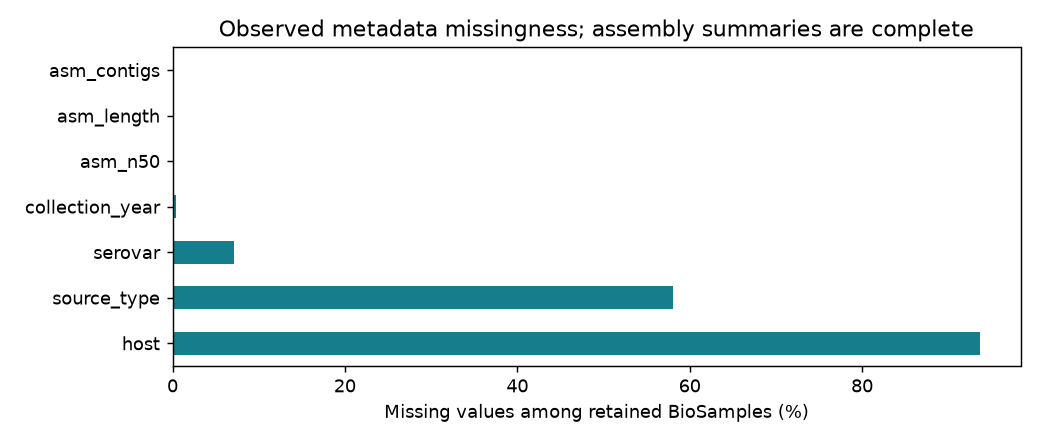

In [4]:
display(pd.DataFrame([{'source_label':'susceptible','binary_target':0,'policy':'eligible if repeats agree'},
                      {'source_label':'resistant','binary_target':1,'policy':'eligible if repeats agree'},
                      {'source_label':'intermediate / nonsusceptible / undefined','binary_target':None,
                       'policy':'audit; excluded from primary binary target'}]))
display(pairs.groupby('status').size().rename('pairs').reset_index())
display(pd.read_csv(ROOT / 'results/audit/phenotype_pair_quarantine.csv.gz').head(8))
missing = pd.read_csv(ROOT / 'results/audit/isolate_feature_missingness.csv')
focus = ['host','source_type','serovar','collection_year','asm_n50','asm_length','asm_contigs']
display(missing[missing['field'].isin(focus)])
assert int(features['collection_year'].isna().sum()) == 40
assert features[['asm_n50','asm_length','asm_contigs']].notna().all().all()
table = missing.set_index('field').loc[focus,'missing_percent']
fig, ax = plt.subplots(figsize=(8,3.4))
table.plot.barh(ax=ax, color='#167d8d')
ax.set(xlabel='Missing values among retained BioSamples (%)', ylabel='',
       title='Observed metadata missingness; assembly summaries are complete')
fig.tight_layout(); buffer=BytesIO(); fig.savefig(buffer,format='png',dpi=130)
display(Image(data=buffer.getvalue())); plt.close(fig)


### 4. Keep related isolates together before learning transformations

The primary split assigns recorded SNP/BioSample connected components to
training, validation and test using fixed seeds. Group proportions are
approximately 60/20/20; unequal group sizes can make isolate proportions
differ. Missing SNP links fall back to BioSample grouping, and are not proof
of biological independence.

MIC, disk measurements, AST-derived counts and source phenotype summaries
are excluded from predictors. Identifiers serve linkage and split audit.
Imputers, scalers, category vocabularies and the gene vocabulary learn from
training only, including separately within the group-aware CV folds.


In [5]:
splits = pd.read_csv(model_dir / 'split_manifest.csv.gz')
split_sets = {s:set(splits.loc[splits['split'].eq(s),'group_id']) for s in ['train','validation','test']}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not split_sets[a].intersection(split_sets[b]), f'Component overlap: {a}/{b}'
assert splits['biosample_acc'].is_unique
display(splits.groupby('split').agg(biosamples=('biosample_acc','size'), groups=('group_id','nunique')))
display(pd.DataFrame([{'drug':drug,'split':split,**info}
                      for drug,task in study['tasks'].items() for split,info in task['splits'].items()]))
print('Recorded SNP/BioSample components:', prep['connected_groups'],
      '| largest retained component:', prep['largest_group_isolates'])
print(study['protocol'])


,biosamples,groups
split,,
test,2086,250
train,6317,749
validation,1572,250


,drug,split,n,groups,support
0,ampicillin,train,6268,732,"{'susceptible': 4465, 'resistant': 1803}"
1,ampicillin,validation,1538,244,"{'susceptible': 1298, 'resistant': 240}"
2,ampicillin,test,2070,242,"{'susceptible': 1587, 'resistant': 483}"
3,tetracycline,train,6232,722,"{'resistant': 3350, 'susceptible': 2882}"
4,tetracycline,validation,1529,242,"{'susceptible': 1002, 'resistant': 527}"
5,tetracycline,test,2053,243,"{'resistant': 1110, 'susceptible': 943}"
6,ciprofloxacin,train,6021,711,"{'susceptible': 5337, 'resistant': 684}"
7,ciprofloxacin,validation,1505,235,"{'susceptible': 1466, 'resistant': 39}"
8,ciprofloxacin,test,2058,241,"{'susceptible': 2023, 'resistant': 35}"


Recorded SNP/BioSample components: 1249 | largest retained component: 683
Fixed 60/20/20 SNP/BioSample connected-component split; seed 42/43.


### 5. Inspect fitted encodings instead of inventing integer meanings

Nominal categories have no natural numerical spacing. Ordinal codes are an
explicit comparison baseline, while one-hot encoding assigns separate columns.
A categorical missing token records missingness without guessing the value.
Each arm uses its fitted training vocabulary; the saved maps state unseen-value
behavior. Gene annotations are **symbol=status multi-hot presence** features,
not gene copy number or newly inferred sequence mechanisms.

Median, median plus missing indicators, and single deterministic iterative
imputation are controlled alternatives. Iterative imputation is not pooled
multiple-imputation inference, and additional complexity need not improve results.


In [6]:
import joblib
import model_study as modeling  # Import custom GeneEncoder before loading the frozen joblib pipeline.
from model_study import feature_columns, CATEGORICAL, BASE_NUMERIC, GENOMIC_NUMERIC
primary_name = study['primary_model']
encoding_maps = json.loads((model_dir / 'encoding_maps.json').read_text())
mapping = encoding_maps[primary_name]
forbidden = {'phenotype','AST_phenotypes','mic','disk_diffusion','number_drugs_resistant',
             'number_drugs_susceptible','number_drugs_tested','biosample_acc','target_acc','group_id','bioproject_acc'}
assert not set(feature_columns('combined')).intersection(forbidden)
print('Predictor columns:', feature_columns('combined'))
display(pd.DataFrame([{'feature':key,'training_categories':len(values),'first_categories':list(values)[:6]}
                      for key,values in mapping['categorical_maps'].items()]))
print('Unknown-category policy:', mapping['unknown_category_policy'])
print('Gene vocabulary size:',len(mapping['gene_vocabulary']), '| policy:', mapping['unknown_gene_policy'])
print('Numeric imputation columns:',mapping['numeric_columns'])
print('Numeric indicator indices:',mapping['indicator_feature_indices'])
display(pd.DataFrame(study.get('unseen_gene_tokens',{})).T)
integer_export = ROOT / 'data/processed/ampicillin_label_encoded_train.csv.gz'
if integer_export.exists():
    example = pd.read_csv(integer_export,nrows=5)
    print('Explicit unscaled integer-label export (training vocabulary only):')
    display(example[['biosample_acc','y_resistant','source_type_label','country_label',
                     'host_label','serovar_label','collection_year_imputed','collection_year_was_missing']])
    print('Maps and unknown code:',ROOT / 'results/label_encoding_export.json')


Predictor columns: ['source_type', 'epi_type', 'country', 'host', 'serovar', 'collection_year', 'asm_n50', 'asm_length', 'asm_contigs', 'amr_analysis_available', 'gene_count', 'gene_tokens']


,feature,training_categories,first_categories
0,source_type,5,"[__MISSING__, animal, environmental, food, human]"
1,epi_type,2,"[clinical, environmental/other]"
2,country,10,"[Colombia, Germany, Mexico, Nigeria, Oman, Pak..."
3,host,8,"[__MISSING__, anas, bovine, chicken broiler, g..."
4,serovar,122,"[""i -:e,h:1,5"", ""i -:r:1,5"", -:r:1,5, 3,10:-:l..."


Unknown-category policy: all-zero encoding for unseen category; no rare pooling in either encoding arm
Gene vocabulary size: 196 | policy: Unseen tokens ignored; counts audited separately.
Numeric imputation columns: ['collection_year', 'asm_n50', 'asm_length', 'asm_contigs', 'amr_analysis_available', 'gene_count']
Numeric indicator indices: [0]


,n_isolates_with_unseen_token,n_unique_unseen_tokens
validation,23,25
test,275,23


Explicit unscaled integer-label export (training vocabulary only):


,biosample_acc,y_resistant,source_type_label,country_label,host_label,serovar_label,collection_year_imputed,collection_year_was_missing
0,SAMN02053837,0,0,8,0,39,2012.0,0
1,SAMN02640777,0,3,8,0,56,2002.0,0
2,SAMN02640783,0,3,8,0,83,2002.0,0
3,SAMN02640788,0,3,8,0,48,2002.0,0
4,SAMN02640789,0,3,8,0,116,2002.0,0


Maps and unknown code: /mnt/c/Users/USER/OneDrive/Desktop/Internship_Research_Prime/results/label_encoding_export.json


### 6. Read performance using the declared task, split and threshold

Ampicillin compares six preprocessing combinations, plus metadata-only and
genes-only controls. The primary model remains fixed rather than chosen after
inspecting the test table. Secondary drugs use the declared main configuration
and controls. Read support, resistance recall and precision alongside average
precision (AP), ROC AUC, balanced accuracy and calibration.

The table below selects the **fixed 0.5** threshold. Validation-selected
thresholds are separately labeled in the results CSV. AP is threshold-free;
its reference level depends on resistance frequency. Confusion counts and
calibration reveal behavior that an accuracy percentage can conceal.


,drug,model,n,n_resistant,average_precision,roc_auc,balanced_accuracy,resistance_recall,precision,f1,brier,accuracy
1,ampicillin,ordinal_median,2070.0,483.0,0.9769,0.9887,0.9754,0.9565,0.9809,0.9686,0.0138,0.9855
4,ampicillin,ordinal_median_flags,2070.0,483.0,0.9769,0.9887,0.9754,0.9565,0.9809,0.9686,0.0138,0.9855
7,ampicillin,ordinal_iterative_flags,2070.0,483.0,0.9769,0.9887,0.9754,0.9565,0.9809,0.9686,0.0138,0.9855
10,ampicillin,onehot_median,2070.0,483.0,0.9751,0.9888,0.9744,0.9545,0.9809,0.9675,0.0143,0.9850
13,ampicillin,onehot_median_flags,2070.0,483.0,0.9750,0.9888,0.9744,0.9545,0.9809,0.9675,0.0143,0.9850
16,ampicillin,onehot_iterative_flags,2070.0,483.0,0.9750,0.9888,0.9744,0.9545,0.9809,0.9675,0.0143,0.9850
19,ampicillin,metadata_only,2070.0,483.0,0.5552,0.8332,0.6971,0.5114,0.5704,0.5393,0.1397,0.7961
22,ampicillin,genes_only,2070.0,483.0,0.9754,0.9868,0.9754,0.9565,0.9809,0.9686,0.0134,0.9855
25,tetracycline,onehot_median_flags,2053.0,1110.0,0.9920,0.9905,0.9906,0.9865,0.9955,0.9910,0.0116,0.9903
28,tetracycline,metadata_only,2053.0,1110.0,0.7867,0.7716,0.6763,0.5063,0.7949,0.6186,0.2139,0.6624


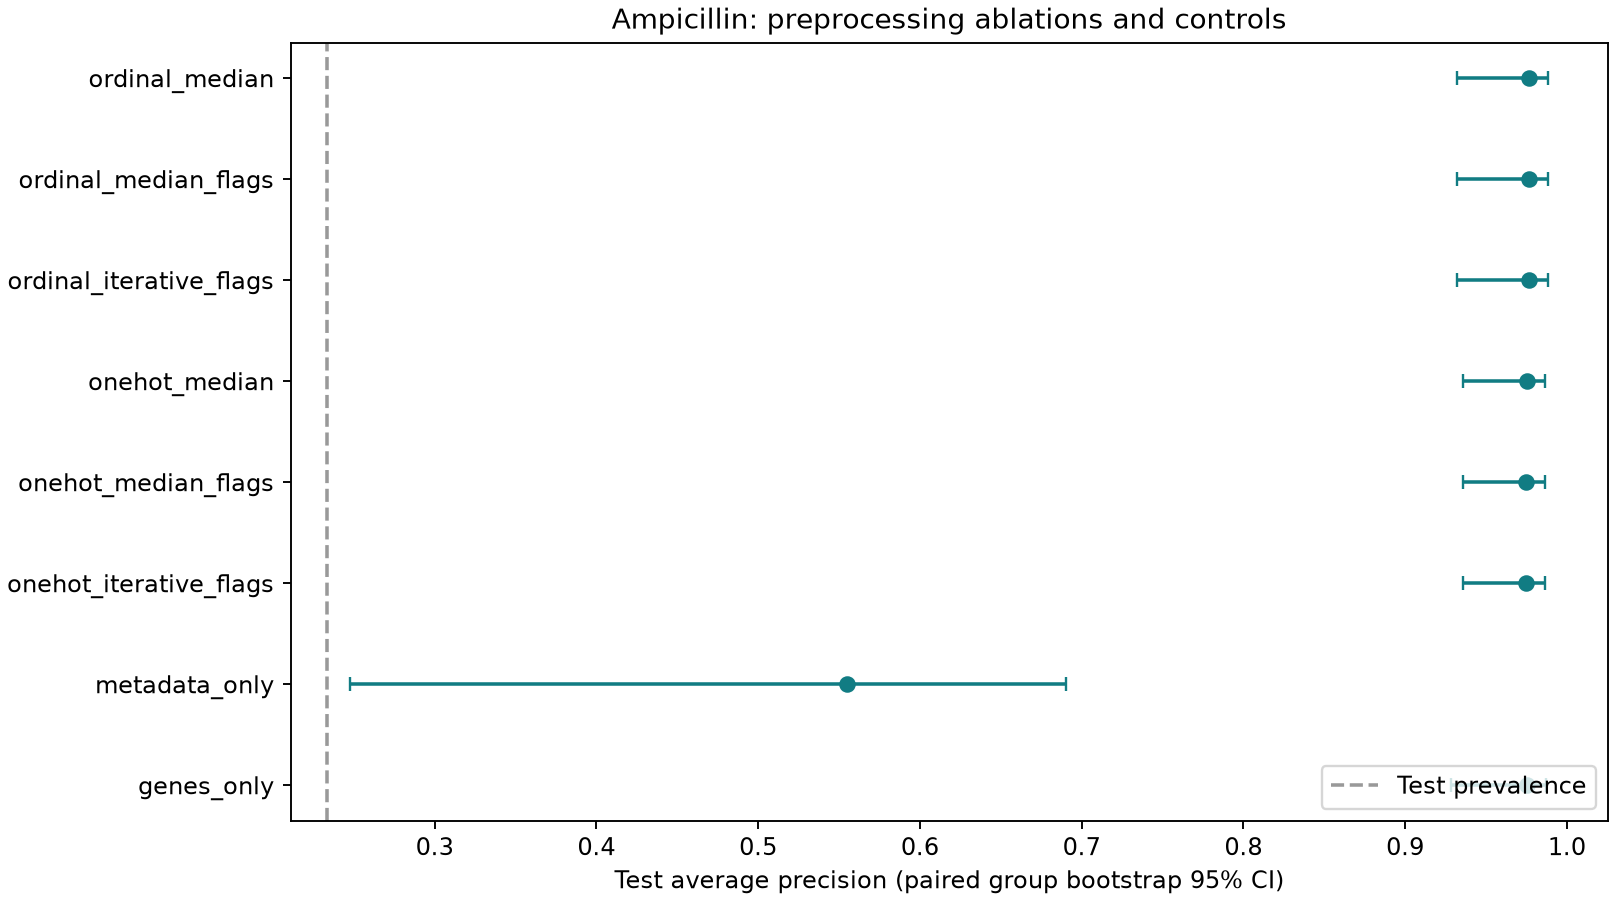

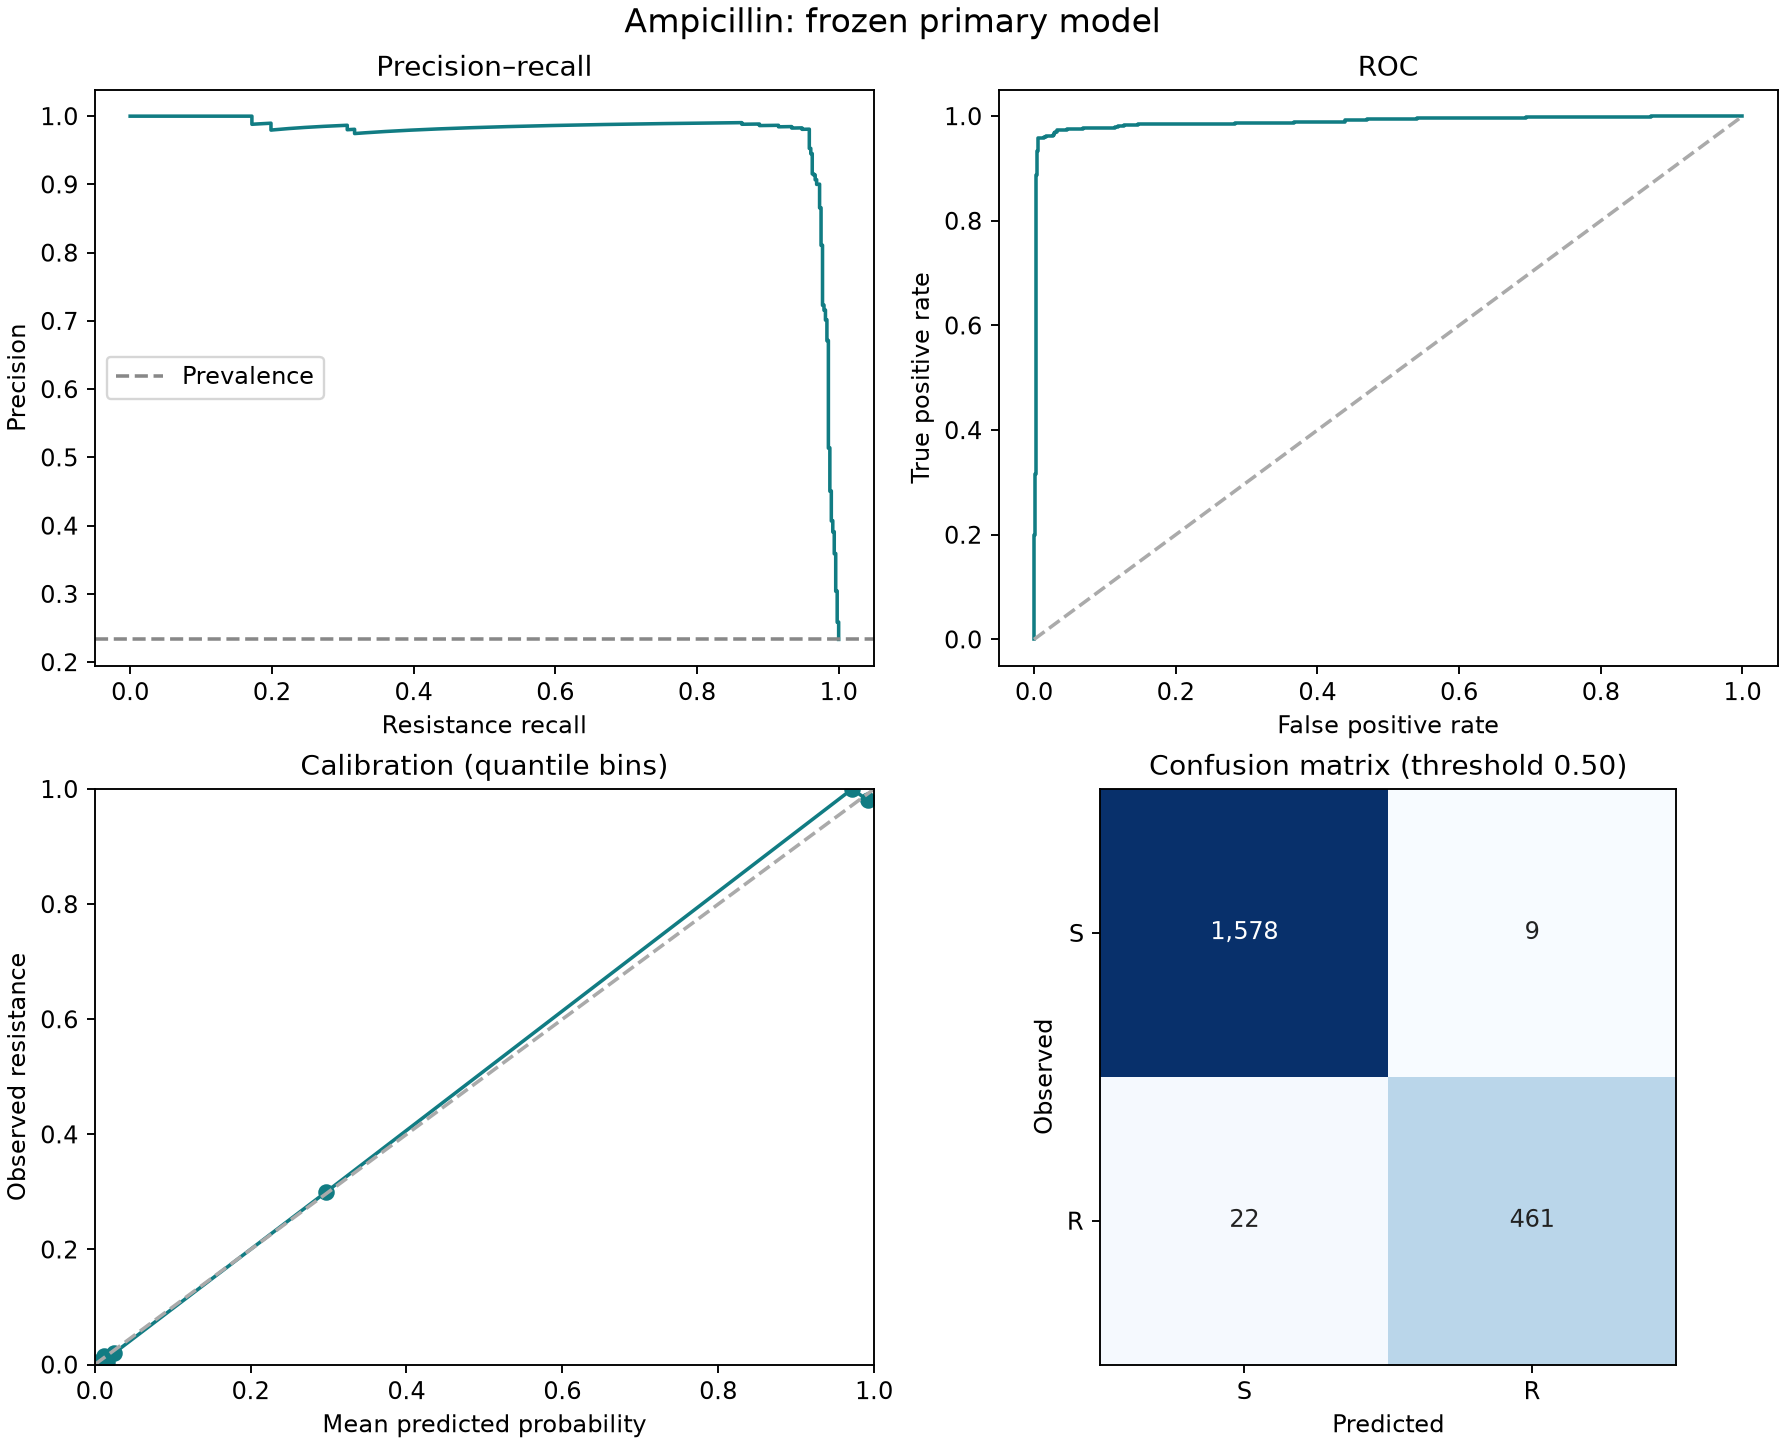

Actual measured results; diagnostics above use the frozen main model and declared threshold.


In [7]:
metrics = pd.read_csv(model_dir / 'metrics.csv')
fixed = metrics[metrics['split'].eq('test') & metrics['threshold_policy'].eq('fixed_0.5')]
columns = ['drug','model','n','n_resistant','average_precision','roc_auc','balanced_accuracy',
           'resistance_recall','precision','f1','brier','accuracy']
display(fixed[columns].round(4))
assert {'metadata_only','genes_only',primary_name}.issubset(set(fixed['model']))
display(Image(filename=str(model_dir / 'figures/ampicillin_ablation_average_precision.png')))
display(Image(filename=str(model_dir / 'figures/ampicillin_diagnostics.png')))
print('Actual measured results; diagnostics above use the frozen main model and declared threshold.')


### 7. Quantify uncertainty and challenge the split

Training-fold group-aware CV and paired resampling of test groups address
recorded dependence. Bootstrap confidence intervals are conditional on fitted
models and the frozen split: they do not capture all training uncertainty or
repair noisy laboratory labels.

A BioSample-random diagnostic may place clonal relatives across the boundary.
BioProject-component holdout probes submission/project shifts and can have
difficult class support. These analyses answer different questions; none is
automatic proof of external, temporal or clinical validity. A confidence
interval crossing zero in a paired difference does not support a clear gain.


In [8]:
cv = pd.read_csv(model_dir / 'cv_metrics.csv')
ci = pd.read_csv(model_dir / 'bootstrap_ci.csv')
differences = pd.read_csv(model_dir / 'paired_differences.csv')
sensitivities = pd.read_csv(model_dir / 'split_sensitivities.csv')
display(cv.round(4))
display(ci[ci['metric'].isin(['average_precision','resistance_recall'])].round(4))
display(differences[differences['metric'].eq('average_precision')].round(4))
display(sensitivities.round(4))
print('Bootstrap design:', study['bootstrap'])
print('Warnings recorded by the actual run:', {k:v for k,v in study.get('warnings',{}).items() if v})


,drug,model,fold,n_training,n_validation,fit_seconds,n,n_resistant,n_susceptible,prevalence,...,balanced_accuracy,f1,resistance_recall,precision,brier,accuracy,tn,fp,fn,tp
0,ampicillin,ordinal_median,1,4221,2047,0.1508,2047.0,574.0,1473.0,0.2804,...,0.8904,0.8342,0.8589,0.8109,0.0653,0.9043,1358.0,115.0,81.0,493.0
1,ampicillin,ordinal_median,2,4090,2178,0.1053,2178.0,640.0,1538.0,0.2938,...,0.9679,0.9647,0.9391,0.9917,0.0244,0.9798,1533.0,5.0,39.0,601.0
2,ampicillin,ordinal_median,3,4225,2043,0.1797,2043.0,589.0,1454.0,0.2883,...,0.9867,0.9821,0.9796,0.9846,0.0102,0.9897,1445.0,9.0,12.0,577.0
3,ampicillin,ordinal_median_flags,1,4221,2047,0.2073,2047.0,574.0,1473.0,0.2804,...,0.8904,0.8342,0.8589,0.8109,0.0657,0.9043,1358.0,115.0,81.0,493.0
4,ampicillin,ordinal_median_flags,2,4090,2178,0.1737,2178.0,640.0,1538.0,0.2938,...,0.9679,0.9647,0.9391,0.9917,0.0245,0.9798,1533.0,5.0,39.0,601.0
5,ampicillin,ordinal_median_flags,3,4225,2043,0.1870,2043.0,589.0,1454.0,0.2883,...,0.9867,0.9821,0.9796,0.9846,0.0102,0.9897,1445.0,9.0,12.0,577.0
6,ampicillin,ordinal_iterative_flags,1,4221,2047,0.2391,2047.0,574.0,1473.0,0.2804,...,0.8904,0.8342,0.8589,0.8109,0.0659,0.9043,1358.0,115.0,81.0,493.0
7,ampicillin,ordinal_iterative_flags,2,4090,2178,0.2306,2178.0,640.0,1538.0,0.2938,...,0.9679,0.9647,0.9391,0.9917,0.0245,0.9798,1533.0,5.0,39.0,601.0
8,ampicillin,ordinal_iterative_flags,3,4225,2043,0.2378,2043.0,589.0,1454.0,0.2883,...,0.9867,0.9821,0.9796,0.9846,0.0102,0.9897,1445.0,9.0,12.0,577.0
9,ampicillin,onehot_median,1,4221,2047,0.1494,2047.0,574.0,1473.0,0.2804,...,0.8901,0.8335,0.8589,0.8095,0.0654,0.9038,1357.0,116.0,81.0,493.0


,model,metric,estimate,ci_lower,ci_upper,valid_replicates
0,ordinal_median,average_precision,0.9769,0.9323,0.9883,300
4,ordinal_median,resistance_recall,0.9565,0.8933,0.9797,300
8,ordinal_median_flags,average_precision,0.9769,0.9323,0.9883,300
12,ordinal_median_flags,resistance_recall,0.9565,0.8933,0.9797,300
16,ordinal_iterative_flags,average_precision,0.9769,0.9323,0.9883,300
20,ordinal_iterative_flags,resistance_recall,0.9565,0.8933,0.9797,300
24,onehot_median,average_precision,0.9751,0.9360,0.9865,300
28,onehot_median,resistance_recall,0.9545,0.8933,0.9768,300
32,onehot_median_flags,average_precision,0.9750,0.9356,0.9864,300
36,onehot_median_flags,resistance_recall,0.9545,0.8933,0.9768,300


,model,reference,metric,difference,ci_lower,ci_upper,valid_replicates
0,ordinal_median,onehot_median_flags,average_precision,0.0019,-0.0033,0.0048,300
3,ordinal_median_flags,onehot_median_flags,average_precision,0.0019,-0.0033,0.0048,300
6,ordinal_iterative_flags,onehot_median_flags,average_precision,0.0019,-0.0033,0.0049,300
9,onehot_median,onehot_median_flags,average_precision,0.0001,-0.0001,0.0002,300
12,onehot_iterative_flags,onehot_median_flags,average_precision,-0.0000,-0.0000,0.0000,300
15,metadata_only,onehot_median_flags,average_precision,-0.4197,-0.7039,-0.2888,300
18,genes_only,onehot_median_flags,average_precision,0.0004,-0.0070,0.0029,300


,analysis,status,fit_seconds,n_train,test_rows_with_training_SNP_component,n,n_resistant,n_susceptible,prevalence,threshold,...,balanced_accuracy,f1,resistance_recall,precision,brier,accuracy,tn,fp,fn,tp
0,biosample_random_clone_overlap_diagnostic,evaluated,0.3315,5913,1784,1979.0,496.0,1483.0,0.2506,0.5,...,0.9664,0.9588,0.9395,0.979,0.0190,0.9798,1473.0,10.0,30.0,466.0
1,bioproject_component_holdout,evaluated,0.1213,2778,4069,5307.0,1111.0,4196.0,0.2093,0.5,...,0.9501,0.8798,0.9586,0.813,0.0454,0.9452,3951.0,245.0,46.0,1065.0


Bootstrap design: {'replicates': 300, 'unit': 'SNP/BioSample connected component', 'paired': True, 'method': 'percentile 95%; frozen models, threshold 0.5', 'scope': 'Conditional on fitted training models; excludes training/model-selection uncertainty.'}
Warnings recorded by the actual run: {}


### 8. Missingness stress experiments and processing scale

Natural numerical missingness is limited here. A separately declared stress
experiment masks **observed validation cells** under simulated MCAR and
assembly-contig-conditioned MAR mechanisms, without target/test-set use.
Reconstruction error on those known values cannot establish the truth of
naturally missing values or identify the source's real missingness mechanism.

The streaming benchmark processes real ordered source prefixes and the full
collection with different chunk sizes. Equal canonical hashes check semantic
equivalence. It measures row normalization/measurement parsing, not full joins,
training, distributed Spark performance or a larger biological sample size.
Single-run timing depends on startup, cache and run order.


In [9]:
stress_path = ROOT / 'results/imputation_stress.csv'
if stress_path.exists():
    stress = pd.read_csv(stress_path)
    design = json.loads((ROOT / 'results/imputation_stress_design.json').read_text())
    print('Stress design:', design)
    display(stress[['mechanism','method','feature','observed_validation_cells_masked',
                    'rmse_original_units','rmse_over_training_iqr']].round(4))
else:
    print('Optional imputation stress results are not present; no values have been invented.')
benchmark_path = ROOT / 'results/streaming_benchmark.json'
if benchmark_path.exists():
    benchmark = json.loads(benchmark_path.read_text())
    assert benchmark['all_checks_passed']
    display(pd.DataFrame(benchmark['runs'])[['requested_prefix_rows','chunk_size','records_processed',
                                             'transform_seconds','process_wall_seconds','peak_rss_mib']].round(3))
    display(pd.DataFrame(benchmark['chunk_consistency']))
    print('Benchmark scope:', benchmark['scope'])
else:
    print('Optional streaming benchmark has not been run; no extrapolated timing is shown.')


Stress design: {'synthetic_masking_only': True, 'fitted_on': 'training isolates only', 'evaluated_on': 'observed validation cells only', 'target_used': False, 'test_set_used': False, 'n_training': 6317, 'n_validation': 1572, 'features': ['collection_year', 'asm_n50', 'asm_length', 'asm_contigs', 'gene_count'], 'missingness_mechanisms': ['MCAR10%', 'MCAR30%', 'MAR conditional on recorded assembly contigs'], 'limitations': 'Stress experiments cannot identify the accuracy of naturally missing values. MAR is a simulation, not an asserted true missingness mechanism.', 'elapsed_seconds': 0.25950289999997267}


,mechanism,method,feature,observed_validation_cells_masked,rmse_original_units,rmse_over_training_iqr
0,MCAR,training_median,collection_year,160,5.6905,0.6323
1,MCAR,training_median,asm_n50,150,563422.6738,3.1665
2,MCAR,training_median,asm_length,137,161669.9945,0.6328
3,MCAR,training_median,asm_contigs,143,45.0415,0.9384
4,MCAR,training_median,gene_count,138,2.7636,0.6909
5,MCAR,iterative_bayesian_ridge,collection_year,160,5.2802,0.5867
6,MCAR,iterative_bayesian_ridge,asm_n50,150,508624.9780,2.8585
7,MCAR,iterative_bayesian_ridge,asm_length,137,113720.7216,0.4452
8,MCAR,iterative_bayesian_ridge,asm_contigs,143,43.2711,0.9015
9,MCAR,iterative_bayesian_ridge,gene_count,138,2.0855,0.5214


,requested_prefix_rows,chunk_size,records_processed,transform_seconds,process_wall_seconds,peak_rss_mib
0,1000,500,1000,0.076,1.008,55.117
1,1000,5000,1000,0.112,1.096,55.125
2,1000,25000,1000,0.099,1.050,55.117
3,10000,500,10000,0.963,1.903,56.562
4,10000,5000,10000,1.177,2.165,81.883
5,10000,25000,10000,1.110,2.090,81.902
6,50000,500,50000,5.810,6.894,56.562
7,50000,5000,50000,5.765,6.685,83.020
8,50000,25000,50000,5.180,6.042,189.949
9,full,500,142338,18.863,19.716,56.602


,requested_prefix_rows,expected_rows,observed_rows,distinct_canonical_hashes,all_chunks_same_output
0,1000,1000,[1000],1,True
1,10000,10000,[10000],1,True
2,50000,50000,[50000],1,True
3,full,142338,[142338],1,True


Benchmark scope: Frozen-source AST row canonicalization and MIC/disk interval parsing only; no joins, deduplication, model fitting or predictive-quality comparison.


### 9. Check the frozen inference path

Loading the model also loads its learned preprocessing. We import the custom
encoder module from this project's src directory before deserialization, and
predict a small set of already-held-out rows. Stored and reloaded probabilities
should agree. This check does not refit or improve the model.

A separate perturbed probe checks supported behavior for unseen categories,
unknown gene tokens and missing numerical values. Its output is a software
robustness test on altered inputs, not additional experimental performance.


In [10]:
model = joblib.load(model_dir / f'models/ampicillin_{primary_name}.joblib')
stored = pd.read_csv(model_dir / 'predictions.csv.gz')
heldout = stored[stored['drug'].eq('ampicillin') & stored['model'].eq(primary_name)
                 & stored['split'].eq('test')].head(6).copy()
probe = heldout[['biosample_acc']].merge(features,on='biosample_acc',validate='one_to_one')
probability = model.predict_proba(probe[feature_columns('combined')])[:,1]
assert np.allclose(probability,heldout['probability'].to_numpy(),atol=1e-10,rtol=0)
heldout['reloaded_probability'] = probability
display(heldout[['biosample_acc','y','probability','reloaded_probability']].round(7))
perturbed = probe.copy()
perturbed.loc[:,CATEGORICAL] = '__UNSEEN_NOTEBOOK_PROBE__'
for column in BASE_NUMERIC + GENOMIC_NUMERIC:
    perturbed[column] = np.nan
perturbed['gene_tokens'] = json.dumps(['__UNSEEN_NOTEBOOK_GENE__=COMPLETE'])
assert np.isfinite(model.predict_proba(perturbed[feature_columns('combined')])).all()
print('Frozen predictions agree; unknown/missing-input software probe returned finite probabilities.')


,biosample_acc,y,probability,reloaded_probability
15970,SAMN02640778,0,0.012264,0.012264
15971,SAMN02640779,0,0.010234,0.010234
15972,SAMN02640780,0,0.011543,0.011543
15973,SAMN02640781,0,0.012567,0.012567
15974,SAMN02640782,0,0.012259,0.012259
15975,SAMN02640784,0,0.010138,0.010138


Frozen predictions agree; unknown/missing-input software probe returned finite probabilities.


### 10. What the evidence can and cannot support

The data are selected surveillance/research submissions with incomplete
source/host fields. Laboratory standards and editions are not fully harmonized;
source S/I/R labels are preserved rather than recomputed using guessed
breakpoints. Recorded clusters do not encode all phylogenetic relationships.
Existing AMR annotations contain prior biological knowledge and general efflux
calls, so predictive performance is not novel mechanism discovery or causality.
Small/uncertain ablation differences are valid findings. An external source
and an independently specified follow-up protocol would strengthen generalization.

**Reproduce the full pipeline in WSL from the project directory:**
```bash
bash setup_wsl.sh && bash run_wsl.sh
```
**Re-execute this walkthrough after those artifacts exist:**
```bash
/tmp/shadman_amr_prime_venv/bin/python src/build_notebook.py --project-root .
```
Redownload is a separate opt-in operation: `bash download_wsl.sh`. It refuses
to replace the frozen snapshot. Exact source URLs, timestamps and hashes are
retained in the acquisition manifest. The initial downloaded data and earlier
Internship_Research project are preserved. Read README.txt and STUDY_GUIDE.txt
for source-use policies, AI-assistance disclosure and the three-day study plan.


In [11]:
validation = json.loads((ROOT / 'results/preprocessing_validation.json').read_text())
assert validation['all_checks_passed']
assert all(source['sha256_verified'] for source in source_checks)
assert study.get('inference_checks',{}).get('serialized_predictions_match')
display(pd.DataFrame(validation['checks'])[['check','passed']])
print('Walkthrough checks complete:', {'source_hashes':True, 'recorded_split_overlap':0,
      'preprocessing_validation':validation['all_checks_passed'], 'frozen_inference_match':True,
      'full_pipeline_rerun_inside_notebook':False})
print('Use results/model_study/summary.json for actual support, packages, warnings and limitations.')


,check,passed
0,hand_calculated_measurement_semantics,True
1,partial_date_and_text_fixtures,True
2,miniature_end_to_end_duplicate_conflict_join_a...,True
3,frozen_raw_source_sha256_counts_and_ids,True
4,processed_output_contracts_and_reconciliation,True


Walkthrough checks complete: {'source_hashes': True, 'recorded_split_overlap': 0, 'preprocessing_validation': True, 'frozen_inference_match': True, 'full_pipeline_rerun_inside_notebook': False}
Use results/model_study/summary.json for actual support, packages, warnings and limitations.
